In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("housing_price_dataset.csv")

In [3]:
df.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,2126,4,1,Rural,1969,215355.283618
1,2459,3,2,Rural,1980,195014.221626
2,1860,2,1,Suburb,1970,306891.012076
3,2294,2,1,Urban,1996,206786.787153
4,2130,5,2,Suburb,2001,272436.239065


In [4]:
df.shape

(50000, 6)

In [5]:
df.dtypes

SquareFeet        int64
Bedrooms          int64
Bathrooms         int64
Neighborhood     object
YearBuilt         int64
Price           float64
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SquareFeet    50000 non-null  int64  
 1   Bedrooms      50000 non-null  int64  
 2   Bathrooms     50000 non-null  int64  
 3   Neighborhood  50000 non-null  object 
 4   YearBuilt     50000 non-null  int64  
 5   Price         50000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 2.3+ MB


In [7]:
df.columns

Index(['SquareFeet', 'Bedrooms', 'Bathrooms', 'Neighborhood', 'YearBuilt',
       'Price'],
      dtype='object')

# Data Preprocessing

In [8]:
df.isna().sum()

SquareFeet      0
Bedrooms        0
Bathrooms       0
Neighborhood    0
YearBuilt       0
Price           0
dtype: int64

In [9]:
df.duplicated().sum()

0

<Axes: ylabel='Density'>

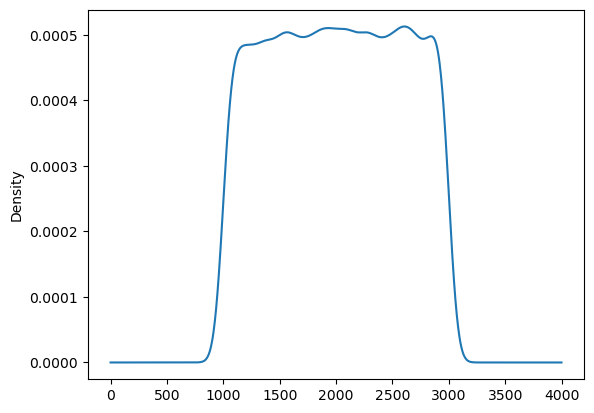

In [10]:
df["SquareFeet"].plot(kind = "kde")

<Axes: ylabel='Frequency'>

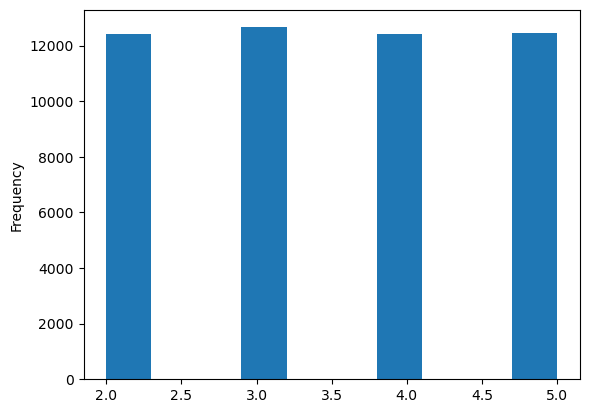

In [11]:
df["Bedrooms"].plot(kind = "hist")

<Axes: ylabel='Frequency'>

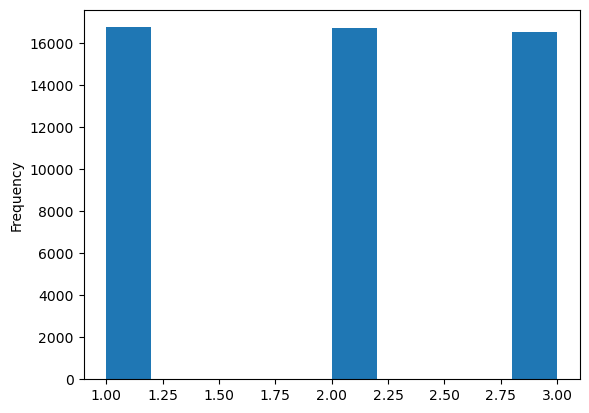

In [12]:
df["Bathrooms"].plot(kind = "hist")

<Axes: xlabel='Neighborhood'>

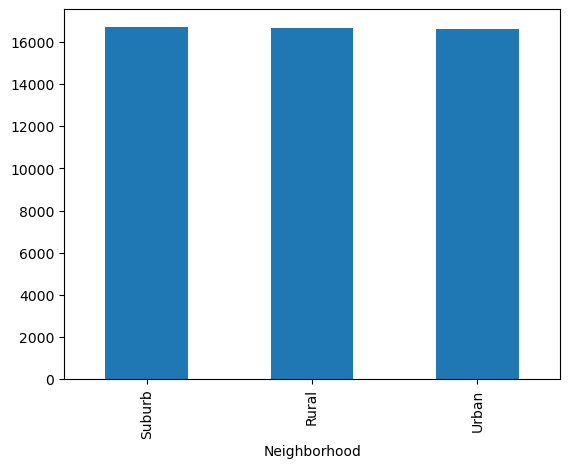

In [13]:
df["Neighborhood"].value_counts().plot(kind = "bar")

<Axes: ylabel='Density'>

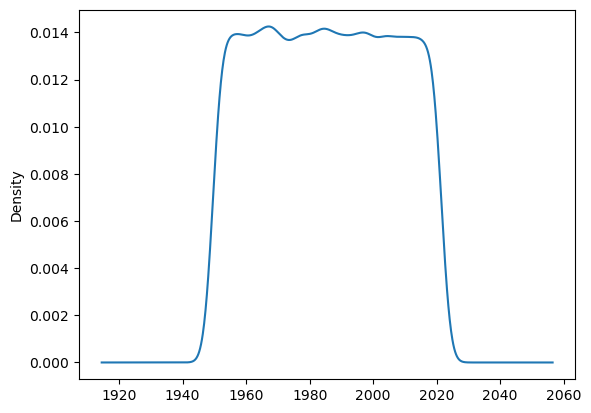

In [14]:
df["YearBuilt"].plot(kind = "kde")

<Axes: >

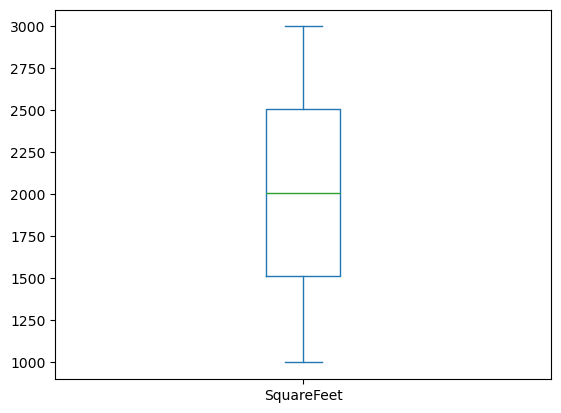

In [15]:
df["SquareFeet"].plot(kind = "box")

<Axes: >

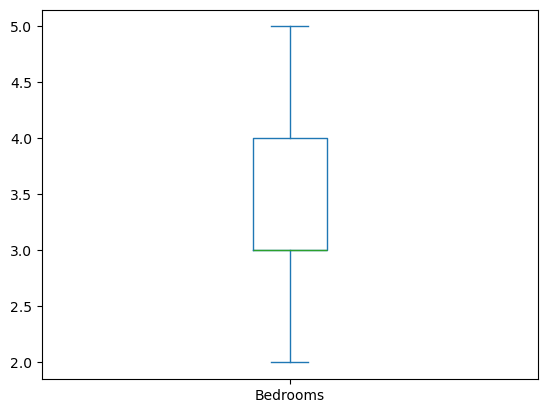

In [16]:
df["Bedrooms"].plot(kind = "box")

<Axes: >

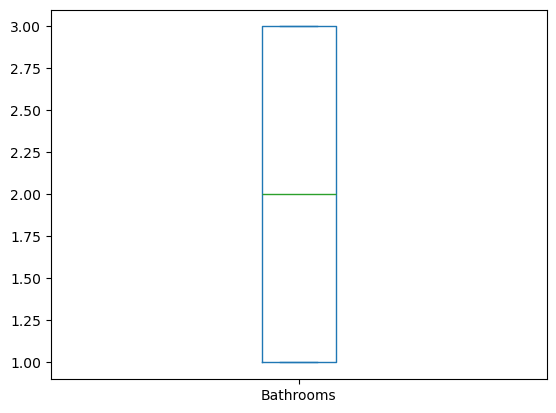

In [17]:
df["Bathrooms"].plot(kind = "box")

<Axes: >

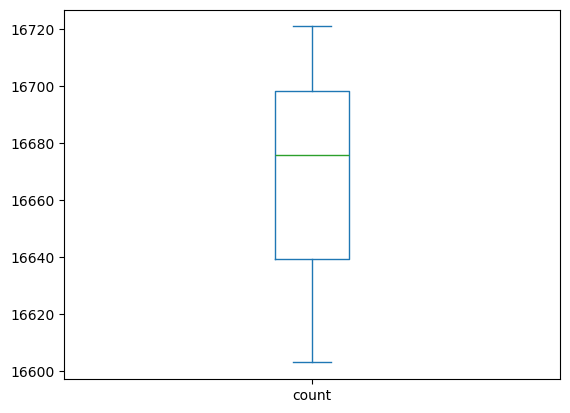

In [18]:
df["Neighborhood"].value_counts().plot(kind = "box")

<Axes: >

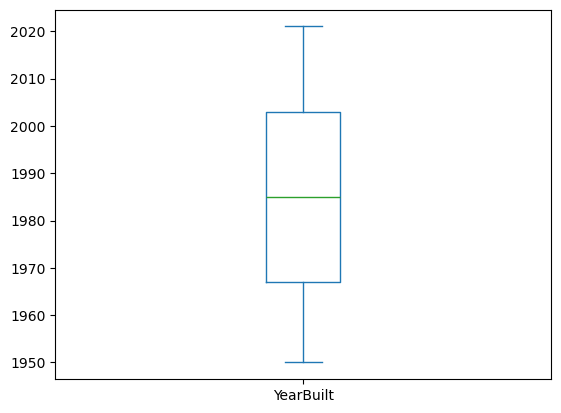

In [19]:
df["YearBuilt"].plot(kind = "box")

In [20]:
df["Price"].min()

-36588.16539749279

In [21]:
df["Price"].max()

492195.25997201505

In [22]:
df["Price"] = np.abs(df["Price"])

In [23]:
df["Price"].min()

154.77912007166017

In [24]:
df["Price"].max()

492195.25997201505

In [25]:
df["Neighborhood"].unique()

array(['Rural', 'Suburb', 'Urban'], dtype=object)

In [26]:
# encode manually

df["Neighborhood"] = df["Neighborhood"].map({"Rural":0, "Suburb":1,"Urban":2})

In [27]:
df.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,2126,4,1,0,1969,215355.283618
1,2459,3,2,0,1980,195014.221626
2,1860,2,1,1,1970,306891.012076
3,2294,2,1,2,1996,206786.787153
4,2130,5,2,1,2001,272436.239065


In [28]:
df.dtypes

SquareFeet        int64
Bedrooms          int64
Bathrooms         int64
Neighborhood      int64
YearBuilt         int64
Price           float64
dtype: object

## Model Building

In [29]:
df.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,2126,4,1,0,1969,215355.283618
1,2459,3,2,0,1980,195014.221626
2,1860,2,1,1,1970,306891.012076
3,2294,2,1,2,1996,206786.787153
4,2130,5,2,1,2001,272436.239065


In [30]:
X = df.drop(columns = ["Price"]) # X contains inputs / features

X.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt
0,2126,4,1,0,1969
1,2459,3,2,0,1980
2,1860,2,1,1,1970
3,2294,2,1,2,1996
4,2130,5,2,1,2001


In [31]:
y = df["Price"]

y.head()

0    215355.283618
1    195014.221626
2    306891.012076
3    206786.787153
4    272436.239065
Name: Price, dtype: float64

In [32]:
import sklearn

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 29
)

In [35]:
X_train.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt
20754,2598,2,1,0,1964
25150,1626,5,3,1,2006
35278,2445,4,1,2,1968
45456,1658,3,2,0,1976
36913,1640,5,3,2,1966


In [36]:
print("The Training Input Shape: ", X_train.shape)
print("The Training Output Shape: ", y_train.shape)

print("-------------------------------------")

print("The Testing Input Shape: ", X_test.shape)
print("The Testing Output Shape: ", y_test.shape)

The Training Input Shape:  (40000, 5)
The Training Output Shape:  (40000,)
-------------------------------------
The Testing Input Shape:  (10000, 5)
The Testing Output Shape:  (10000,)


In [37]:
from sklearn.metrics import root_mean_squared_error

## Linear Regression

In [38]:
from sklearn.linear_model import LinearRegression

### a) Create Model

In [39]:
lr = LinearRegression()

lr

LinearRegression()

In [40]:
lr.fit(X_train, y_train)

LinearRegression()

In [41]:
y_pred = lr.predict(X_test)

print(y_pred)

[190145.57802282 229343.15083813 153026.23321934 ... 236876.07203573
 302191.15291291 257917.69008535]


In [42]:
root_mean_squared_error(y_test, y_pred)

50221.45284824019

## KNN Regressor

In [43]:
from sklearn.neighbors import KNeighborsRegressor

In [44]:
knn = KNeighborsRegressor()

knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print(y_pred)

[249032.40146083 228041.75478998 166785.71286541 ... 247062.19657432
 284017.78608389 234336.72830738]


In [45]:
root_mean_squared_error(y_test, y_pred)

55179.236028770356

## Decision Tree Regressor

In [46]:
from sklearn.tree import DecisionTreeRegressor

In [47]:
dt = DecisionTreeRegressor()

dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

print(y_pred)

[168524.0039686  187359.58164529 152976.46607979 ... 284505.59786719
 297871.71407468 344080.79163663]


In [48]:
root_mean_squared_error(y_test, y_pred)

72567.94289073379

## Model Deployment

In [49]:
import warnings

warnings.filterwarnings('ignore')

In [50]:
sqft = 1700
bed = 2
bath = 1
neighbor = 1
year = 2014
lr.predict([[sqft, bed, bath, neighbor, year]])[0]

183277.04843446426

In [51]:
## Serialization: 

### **Pickle**

- It is a Python Library used to save python objects into files

In [52]:
import pickle

In [53]:
with open(r"model.pkl",'wb') as file:
    pickle.dump(lr, file)

# pickle.dump() = trained model is saved into model.pkl

In [54]:
with open(r"model.pkl","rb") as file:
    model = pickle.load(file)

model

LinearRegression()

In [55]:
def Prediction(sqft, bed, bath, neighbor, year):
    return model.predict([[sqft, bed, bath, neighbor, year]])[0]

In [56]:
pip install gradio

Note: you may need to restart the kernel to use updated packages.


In [57]:
import gradio as gr

In [58]:
iface = gr.Interface(fn = Prediction,
                    title = "House Price Prediction",
                    outputs = gr.Textbox(label = "Predicted Price"),
                    inputs = [
                        gr.Number(label = "SQFT"),
                        gr.Number(label = "No. of Bed Rooms"),
                        gr.Number(label = "No. of Bath Rooms"),
                        gr.Number(label = "Neighbourhood"),
                        gr.Number(label = "Year"),
                    ]
                    )



## Launch Application

### Private 

In [ ]:
iface.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


### Public

In [59]:
iface.launch(share = True)

# share = True --> you will see public url

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
* Running on public URL: https://e9ce6401e013783fe6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
